# Задание 9.5. Кластеризация пациентов с диабетом


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import kruskal

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
RANDOM_STATE = 42

## 1. Загрузка набора данных

- ИМТ — кг/м²;
- давление — мм рт. ст.;
- глюкоза — мг/дл.

In [32]:
diabetes = load_diabetes(scaled=False, as_frame=True)
df = diabetes.frame.copy()
print('Размер:', df.shape)

# проверка: dataset.csv — те же данные, только отмасштабированные и без целевой переменной
if os.path.exists('dataset.csv'):
    csv = pd.read_csv('dataset.csv')
    same = np.allclose(csv.values, load_diabetes(as_frame=True).data.values)
    print('dataset.csv совпадает с load_diabetes:', same)

df.head()

Размер: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [33]:
print(diabetes.DESCR[diabetes.DESCR.find('Attribute Information'):][:900])

Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times the square root of `n_samples` (i.e. the sum of squares of each column totals 1).

Source URL:
https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html

For more information see:
Bradley Efron, Trevor Hastie, Iain Johnstone and Robert Tibshirani (2004) "Least Angle Regression," Annals of Statistics (with discussion), 407-499.
(https://web.stanford.edu/~hastie/Papers/LARS/LeastAngle_2002.p


## 2. Исследование данных

| Признак | Смысл |

 `bmi`  индекс массы тела |
 `bp`  среднее артериальное давление |
 `s6` уровень глюкозы в крови |
 `target`  количественная мера прогрессии заболевания через год (в кластеризации не участвует) |

In [5]:
FEATURES = ['bmi', 'bp', 's6']
NAMES = {'bmi': 'ИМТ', 'bp': 'Давление', 's6': 'Глюкоза'}

data = df[FEATURES + ['target']].copy()
data.info()
print('\nПропуски:', data.isnull().sum().sum(), ' Дубликаты:', data.duplicated().sum())
data.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   bmi     442 non-null    float64
 1   bp      442 non-null    float64
 2   s6      442 non-null    float64
 3   target  442 non-null    float64
dtypes: float64(4)
memory usage: 13.9 KB

Пропуски: 0  Дубликаты: 0


,bmi,bp,s6,target
count,442.00,442.00,442.00,442.00
mean,26.38,94.65,91.26,152.13
std,4.42,13.83,11.50,77.09
min,18.00,62.00,58.00,25.00
25%,23.20,84.00,83.25,87.00
50%,25.70,93.00,91.00,140.50
75%,29.28,105.00,98.00,211.50
max,42.20,133.00,124.00,346.00


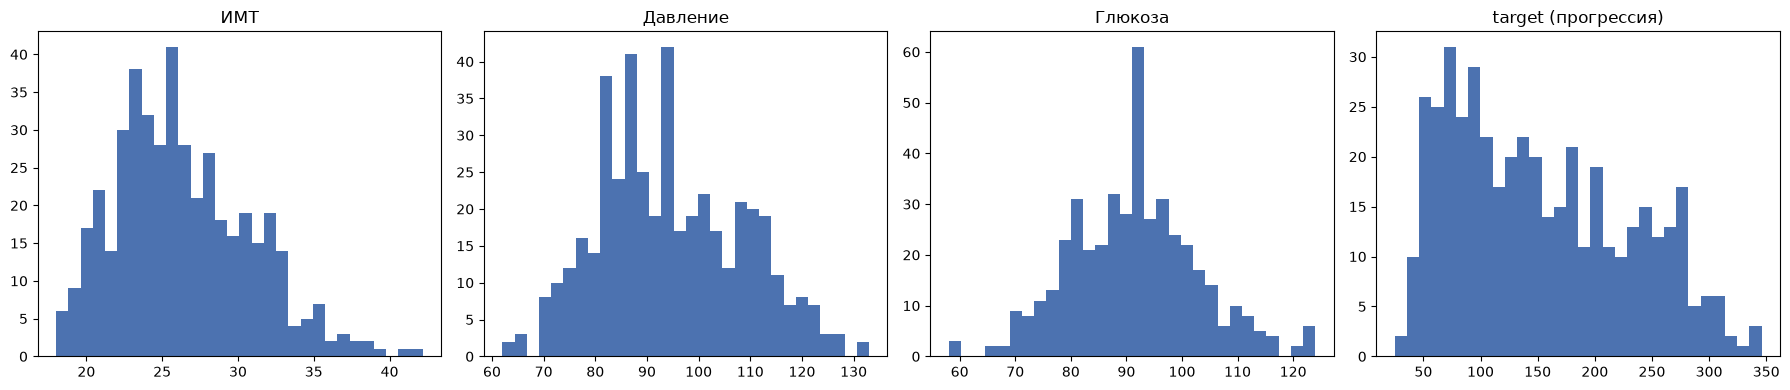

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, FEATURES + ['target']):
    ax.hist(data[col], bins=30, color='#4C72B0')
    ax.set_title(NAMES.get(col, 'target (прогрессия)'))
plt.tight_layout()
plt.show()

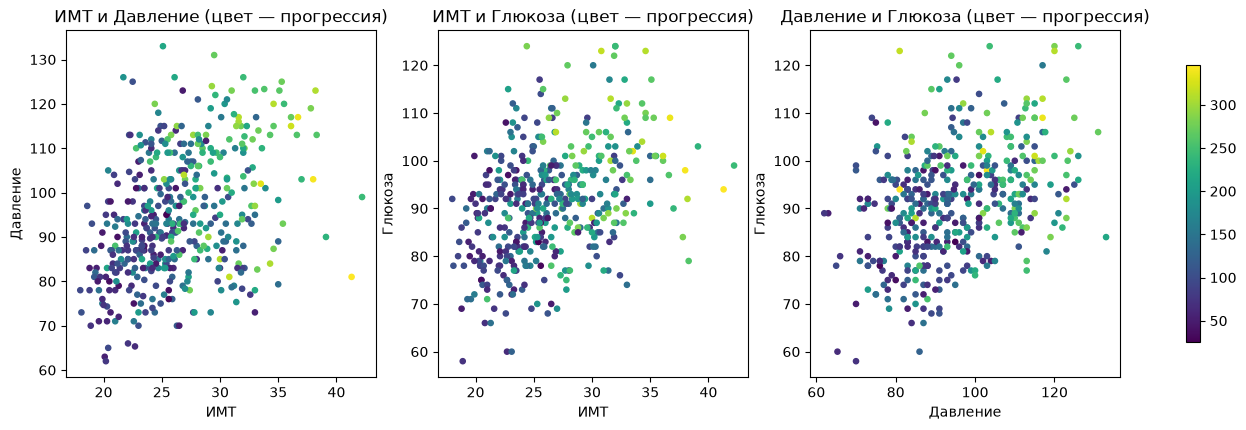

,bmi,bp,s6,target
bmi,1.00,0.40,0.39,0.59
bp,0.40,1.00,0.39,0.44
s6,0.39,0.39,1.00,0.38
target,0.59,0.44,0.38,1.00


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
pairs = [('bmi', 'bp'), ('bmi', 's6'), ('bp', 's6')]
for ax, (x, y) in zip(axes, pairs):
    sc = ax.scatter(data[x], data[y], c=data['target'], cmap='viridis', s=14)
    ax.set_xlabel(NAMES[x]); ax.set_ylabel(NAMES[y])
    ax.set_title(f'{NAMES[x]} и {NAMES[y]} (цвет — прогрессия)')
fig.colorbar(sc, ax=axes, shrink=0.8)
plt.show()

data.corr().round(2)

## 3. Предварительная обработка данных
Признаки измеряются в разных единицах и масштабах:
- ИМТ — примерно 18–42;
- давление — примерно 62–133;
- глюкоза — примерно 58–124.

In [8]:
X_raw = data[FEATURES].values
y = data['target'].values

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
pd.DataFrame(X, columns=FEATURES).describe().round(2)

,bmi,bp,s6
count,442.00,442.00,442.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.90,-2.36,-2.90
25%,-0.72,-0.77,-0.70
50%,-0.15,-0.12,-0.02
75%,0.66,0.75,0.59
max,3.59,2.78,2.85


## 5. Выбор метрики качества (обоснование)


In [13]:
def internal_scores(X, labels):
    mask = labels != -1                     # шум DBSCAN не учитываем
    n_clusters = len(set(labels[mask]))
    if n_clusters < 2 or mask.sum() < 3:
        return {'Кластеров': n_clusters, 'Silhouette': np.nan, 'Davies-Bouldin': np.nan,
                'Calinski-Harabasz': np.nan, 'Доля шума': 1 - mask.mean()}
    return {'Кластеров': n_clusters,
            'Silhouette': silhouette_score(X[mask], labels[mask]),
            'Davies-Bouldin': davies_bouldin_score(X[mask], labels[mask]),
            'Calinski-Harabasz': calinski_harabasz_score(X[mask], labels[mask]),
            'Доля шума': 1 - mask.mean()}

def target_check(labels, y):
    mask = labels != -1
    groups = [y[mask][labels[mask] == c] for c in sorted(set(labels[mask]))]
    if len(groups) < 2:
        return {'eta2 (target)': np.nan, 'p-value (Kruskal)': np.nan}
    grand = y[mask].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((y[mask] - grand) ** 2).sum()
    return {'eta2 (target)': ss_between / ss_total, 'p-value (Kruskal)': kruskal(*groups).pvalue}

## 6. Обучение моделей с разными комбинациями параметров

### 6.1 K-Means: число кластеров от 2 до 8

In [12]:
km_rows, km_labels = [], {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    km_labels[k] = labels
    row = {'Метод': 'K-Means', 'Параметры': f'k={k}', 'Инерция': model.inertia_}
    row.update(internal_scores(X, labels))
    row.update(target_check(labels, y))
    km_rows.append(row)

km_res = pd.DataFrame(km_rows)
km_res.round(3)

,Метод,Параметры,Инерция,Кластеров,Silhouette,Davies-Bouldin,Calinski-Harabasz,Доля шума,eta2 (target),p-value (Kruskal)
0,K-Means,k=2,807.808,2,0.332,1.151,282.251,0.0,0.284,0.0
1,K-Means,k=3,667.775,3,0.249,1.368,216.361,0.0,0.262,0.0
2,K-Means,k=4,555.174,4,0.256,1.273,202.713,0.0,0.341,0.0
3,K-Means,k=5,471.251,5,0.273,1.170,198.156,0.0,0.319,0.0
4,K-Means,k=6,416.058,6,0.274,1.091,190.711,0.0,0.363,0.0
5,K-Means,k=7,376.799,7,0.252,1.104,182.636,0.0,0.358,0.0
6,K-Means,k=8,351.009,8,0.257,1.092,172.216,0.0,0.370,0.0


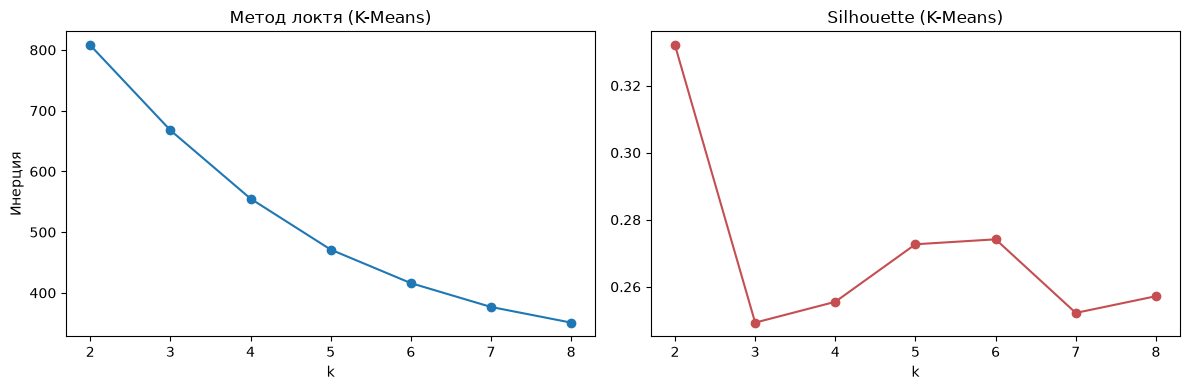

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_res['Кластеров'], km_res['Инерция'], marker='o')
axes[0].set_title('Метод локтя (K-Means)')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Инерция')
axes[1].plot(km_res['Кластеров'], km_res['Silhouette'], marker='o', color='#C44E52')
axes[1].set_title('Silhouette (K-Means)')
axes[1].set_xlabel('k')
plt.tight_layout()
plt.show()

### 6.2 Агломеративная кластеризация: способ связи × число кластеров

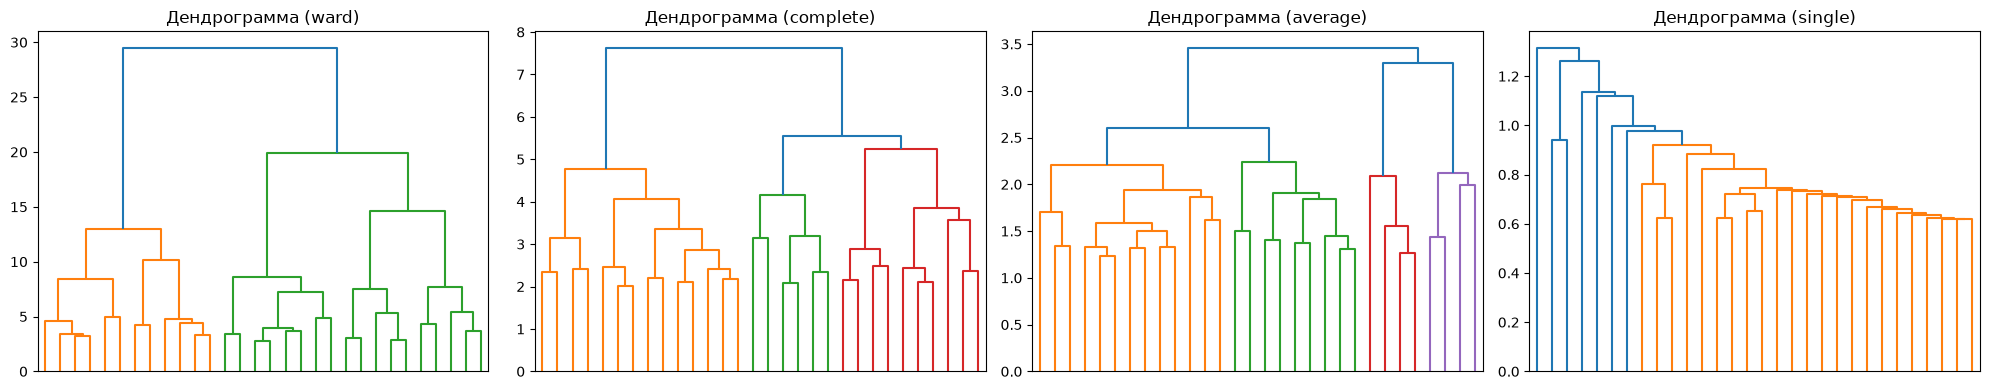

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, method in zip(axes, ['ward', 'complete', 'average', 'single']):
    dendrogram(linkage(X, method=method), ax=ax, truncate_mode='lastp', p=30, no_labels=True)
    ax.set_title(f'Дендрограмма ({method})')
plt.tight_layout()
plt.show()

In [16]:
ag_rows, ag_labels = [], {}
for link in ['ward', 'complete', 'average', 'single']:
    for k in range(2, 9):
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X)
        ag_labels[(link, k)] = labels
        sizes = np.bincount(labels)
        row = {'Метод': 'Иерархическая', 'Параметры': f'{link}, k={k}',
               'Мин. размер кластера': sizes.min()}
        row.update(internal_scores(X, labels))
        row.update(target_check(labels, y))
        ag_rows.append(row)

ag_res = pd.DataFrame(ag_rows)
ag_res.round(3)

,Метод,Параметры,Мин. размер кластера,Кластеров,Silhouette,Davies-Bouldin,Calinski-Harabasz,Доля шума,eta2 (target),p-value (Kruskal)
0,Иерархическая,"ward, k=2",143,2,0.313,1.220,215.320,0.0,0.179,0.000
1,Иерархическая,"ward, k=3",127,3,0.237,1.412,200.474,0.0,0.213,0.000
2,Иерархическая,"ward, k=4",53,4,0.227,1.214,184.312,0.0,0.237,0.000
3,Иерархическая,"ward, k=5",53,5,0.237,1.278,179.265,0.0,0.306,0.000
4,Иерархическая,"ward, k=6",31,6,0.243,1.145,169.171,0.0,0.309,0.000
5,Иерархическая,"ward, k=7",31,7,0.224,1.143,159.877,0.0,0.311,0.000
6,Иерархическая,"ward, k=8",20,8,0.227,1.121,155.521,0.0,0.311,0.000
7,Иерархическая,"complete, k=2",177,2,0.318,1.225,246.888,0.0,0.218,0.000
8,Иерархическая,"complete, k=3",77,3,0.245,1.917,148.731,0.0,0.224,0.000
9,Иерархическая,"complete, k=4",49,4,0.207,1.459,133.209,0.0,0.257,0.000


In [17]:
MIN_SHARE = 0.05
ag_valid = ag_res[ag_res['Мин. размер кластера'] >= MIN_SHARE * len(X)]
print('Допустимых вариантов:', len(ag_valid), 'из', len(ag_res))
ag_valid.sort_values('Silhouette', ascending=False).head(10).round(3)

Допустимых вариантов: 10 из 28


,Метод,Параметры,Мин. размер кластера,Кластеров,Silhouette,Davies-Bouldin,Calinski-Harabasz,Доля шума,eta2 (target),p-value (Kruskal)
7,Иерархическая,"complete, k=2",177,2,0.318,1.225,246.888,0.0,0.218,0.0
0,Иерархическая,"ward, k=2",143,2,0.313,1.220,215.320,0.0,0.179,0.0
8,Иерархическая,"complete, k=3",77,3,0.245,1.917,148.731,0.0,0.224,0.0
4,Иерархическая,"ward, k=6",31,6,0.243,1.145,169.171,0.0,0.309,0.0
1,Иерархическая,"ward, k=3",127,3,0.237,1.412,200.474,0.0,0.213,0.0
3,Иерархическая,"ward, k=5",53,5,0.237,1.278,179.265,0.0,0.306,0.0
2,Иерархическая,"ward, k=4",53,4,0.227,1.214,184.312,0.0,0.237,0.0
5,Иерархическая,"ward, k=7",31,7,0.224,1.143,159.877,0.0,0.311,0.0
9,Иерархическая,"complete, k=4",49,4,0.207,1.459,133.209,0.0,0.257,0.0
10,Иерархическая,"complete, k=5",48,5,0.159,1.429,134.300,0.0,0.269,0.0


### 6.3 DBSCAN: подбор eps и min_samples


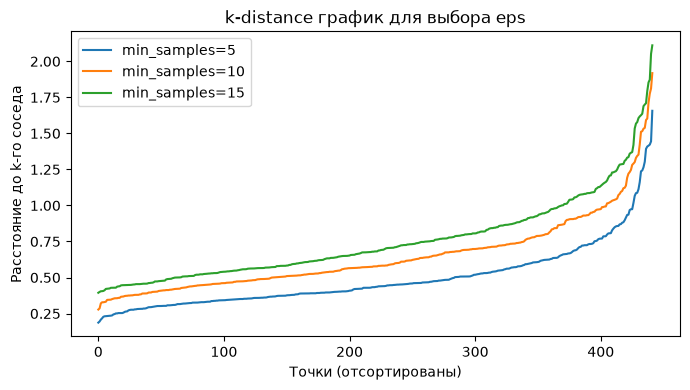

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
for m in [5, 10, 15]:
    dist, _ = NearestNeighbors(n_neighbors=m).fit(X).kneighbors(X)
    ax.plot(np.sort(dist[:, -1]), label=f'min_samples={m}')
ax.set_title('k-distance график для выбора eps')
ax.set_xlabel('Точки (отсортированы)'); ax.set_ylabel('Расстояние до k-го соседа')
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
db_rows, db_labels = [], {}
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    for m in [3, 5, 10, 15]:
        labels = DBSCAN(eps=eps, min_samples=m).fit_predict(X)
        db_labels[(eps, m)] = labels
        row = {'Метод': 'DBSCAN', 'Параметры': f'eps={eps}, min_samples={m}'}
        row.update(internal_scores(X, labels))
        row.update(target_check(labels, y))
        db_rows.append(row)

db_res = pd.DataFrame(db_rows)
db_res.round(3)

,Метод,Параметры,Кластеров,Silhouette,Davies-Bouldin,Calinski-Harabasz,Доля шума,eta2 (target),p-value (Kruskal)
0,DBSCAN,"eps=0.3, min_samples=3",31,0.225,0.756,63.334,0.473,0.388,0.000
1,DBSCAN,"eps=0.3, min_samples=5",6,0.369,0.874,68.399,0.794,0.203,0.004
2,DBSCAN,"eps=0.3, min_samples=10",1,NaN,NaN,NaN,0.971,NaN,NaN
3,DBSCAN,"eps=0.3, min_samples=15",0,NaN,NaN,NaN,1.000,NaN,NaN
4,DBSCAN,"eps=0.4, min_samples=3",9,-0.107,0.791,14.724,0.229,0.140,0.000
5,DBSCAN,"eps=0.4, min_samples=5",4,-0.032,0.946,14.979,0.391,0.042,0.022
6,DBSCAN,"eps=0.4, min_samples=10",2,0.539,0.584,136.708,0.762,0.161,0.000
7,DBSCAN,"eps=0.4, min_samples=15",2,0.612,0.558,80.667,0.930,0.010,0.621
8,DBSCAN,"eps=0.5, min_samples=3",4,0.177,0.811,25.399,0.129,0.108,0.000
9,DBSCAN,"eps=0.5, min_samples=5",3,0.133,0.801,23.742,0.208,0.058,0.001


In [20]:
def db_min_cluster(labels):
    lab = labels[labels != -1]
    return np.bincount(lab).min() if len(lab) else 0

db_res['Мин. размер кластера'] = [db_min_cluster(db_labels[(float(p.split(',')[0].split('=')[1]), int(p.split('=')[2]))])
                                  for p in db_res['Параметры']]
db_valid = db_res[(db_res['Кластеров'] >= 2) & (db_res['Доля шума'] <= 0.2)
                  & (db_res['Мин. размер кластера'] >= MIN_SHARE * len(X))]
print('Допустимых вариантов DBSCAN:', len(db_valid), 'из', len(db_res))
db_valid.sort_values('Silhouette', ascending=False).round(3)

Допустимых вариантов DBSCAN: 0 из 28


,Метод,Параметры,Кластеров,Silhouette,Davies-Bouldin,Calinski-Harabasz,Доля шума,eta2 (target),p-value (Kruskal),Мин. размер кластера


## 7. Оценка качества вариантов моделей по выбранной метрике

In [21]:
cols = ['Метод', 'Параметры', 'Кластеров', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz',
        'Доля шума', 'eta2 (target)', 'p-value (Kruskal)']
km_res['Мин. размер кластера'] = [np.bincount(km_labels[k]).min() for k in km_res['Кластеров']]
km_valid = km_res[km_res['Мин. размер кластера'] >= MIN_SHARE * len(X)]

# если у DBSCAN нет допустимых вариантов, для сравнения берём лучший из вариантов
# с >= 2 кластерами и шумом <= 20% и помечаем его как недопустимый
db_fallback = db_res[(db_res['Кластеров'] >= 2) & (db_res['Доля шума'] <= 0.2)]

best_rows = []
for name, table, fallback in [('K-Means', km_valid, None), ('Иерархическая', ag_valid, None),
                              ('DBSCAN', db_valid, db_fallback)]:
    if len(table):
        row = table.sort_values('Silhouette', ascending=False).iloc[0].copy()
        row['Допустим'] = True
    else:
        row = fallback.sort_values('Silhouette', ascending=False).iloc[0].copy()
        row['Допустим'] = False
        print(f'{name}: допустимых вариантов нет, для сравнения показан {row["Параметры"]} '
              f'(мин. кластер = {int(row["Мин. размер кластера"])} пациентов)')
    best_rows.append(row)

best = pd.DataFrame(best_rows)[cols + ['Мин. размер кластера', 'Допустим']].reset_index(drop=True)
best.round(3)

DBSCAN: допустимых вариантов нет, для сравнения показан eps=0.8, min_samples=3 (мин. кластер = 3 пациентов)


,Метод,Параметры,Кластеров,Silhouette,Davies-Bouldin,Calinski-Harabasz,Доля шума,eta2 (target),p-value (Kruskal),Мин. размер кластера,Допустим
0,K-Means,k=2,2,0.332,1.151,282.251,0.000,0.284,0.000,206,True
1,Иерархическая,"complete, k=2",2,0.318,1.225,246.888,0.000,0.218,0.000,177,True
2,DBSCAN,"eps=0.8, min_samples=3",2,0.358,0.621,11.335,0.023,0.021,0.009,3,False


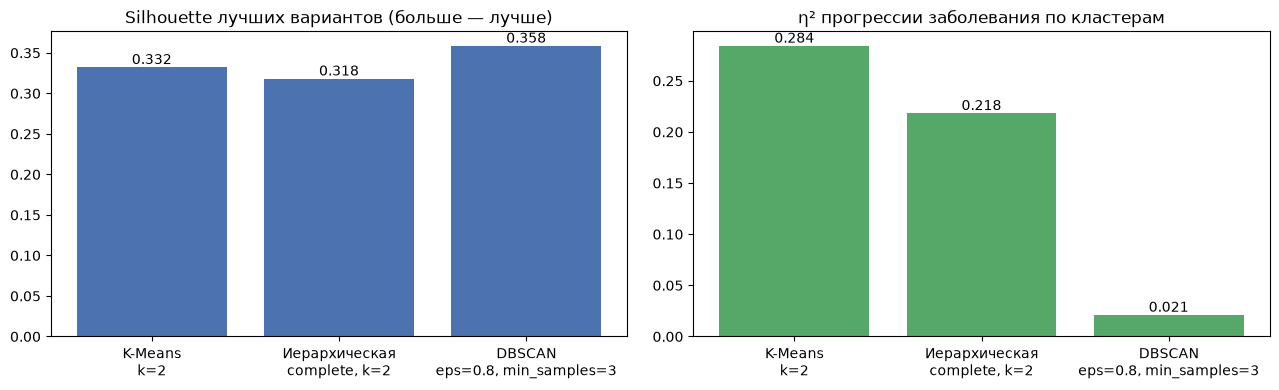

In [22]:
plot = best.dropna(subset=['Silhouette'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
b = axes[0].bar(plot['Метод'] + '\n' + plot['Параметры'], plot['Silhouette'], color='#4C72B0')
axes[0].bar_label(b, fmt='%.3f')
axes[0].set_title('Silhouette лучших вариантов (больше — лучше)')
b = axes[1].bar(plot['Метод'] + '\n' + plot['Параметры'], plot['eta2 (target)'], color='#55A868')
axes[1].bar_label(b, fmt='%.3f')
axes[1].set_title('η² прогрессии заболевания по кластерам')
plt.tight_layout()
plt.show()

## 8. Кластеризация лучшим вариантом и выводы


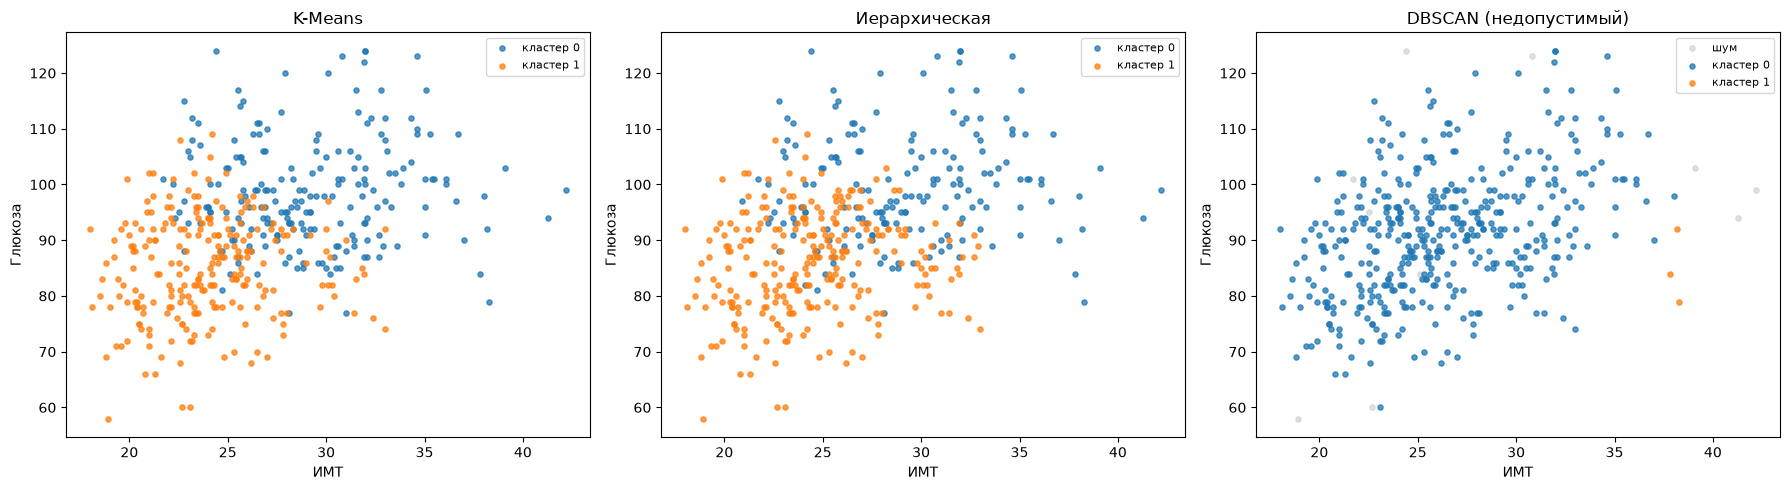

In [24]:
def labels_for(row):
    p = row['Параметры']
    if row['Метод'] == 'K-Means':
        return km_labels[int(p.split('=')[1])]
    if row['Метод'] == 'Иерархическая':
        link, k = p.split(', ')
        return ag_labels[(link, int(k.split('=')[1]))]
    eps, m = p.split(', ')
    return db_labels[(float(eps.split('=')[1]), int(m.split('=')[1]))]

final = {r['Метод'] + ('' if r['Допустим'] else ' (недопустимый)'): labels_for(r)
         for _, r in best.dropna(subset=['Silhouette']).iterrows()}

fig, axes = plt.subplots(1, len(final), figsize=(6 * len(final), 5), squeeze=False)
for ax, (name, labels) in zip(axes[0], final.items()):
    for c in sorted(set(labels)):
        m = labels == c
        ax.scatter(X_raw[m, 0], X_raw[m, 2], s=14, alpha=0.75,
                   label='шум' if c == -1 else f'кластер {c}', color='lightgray' if c == -1 else None)
    ax.set_xlabel('ИМТ'); ax.set_ylabel('Глюкоза')
    ax.set_title(name)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

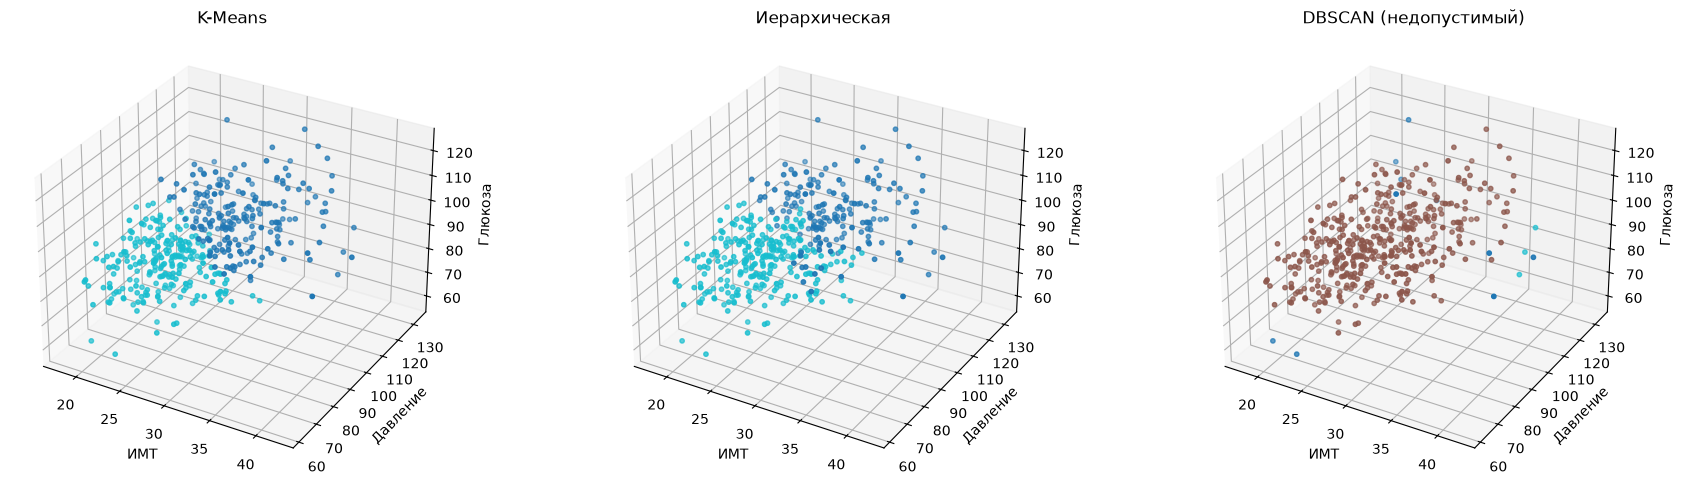

In [25]:
fig = plt.figure(figsize=(6 * len(final), 5))
for i, (name, labels) in enumerate(final.items(), 1):
    ax = fig.add_subplot(1, len(final), i, projection='3d')
    ax.scatter(X_raw[:, 0], X_raw[:, 1], X_raw[:, 2], c=labels, cmap='tab10', s=10)
    ax.set_xlabel('ИМТ'); ax.set_ylabel('Давление'); ax.set_zlabel('Глюкоза')
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Профили кластеров и косвенная проверка по прогрессии заболевания

In [26]:
for name, labels in final.items():
    prof = data.assign(Кластер=labels).groupby('Кластер').agg(
        Пациентов=('target', 'size'),
        ИМТ=('bmi', 'mean'), Давление=('bp', 'mean'), Глюкоза=('s6', 'mean'),
        Прогрессия_среднее=('target', 'mean'), Прогрессия_медиана=('target', 'median')).round(1)
    print(f'===== {name} =====')
    print(prof, '\n')

===== K-Means =====
         Пациентов   ИМТ  Давление  Глюкоза  Прогрессия_среднее  Прогрессия_медиана
Кластер                                                                            
0              206  29.2     104.8     98.5               196.1               198.0
1              236  23.9      85.8     85.0               113.8                97.0 

===== Иерархическая =====
         Пациентов   ИМТ  Давление  Глюкоза  Прогрессия_среднее  Прогрессия_медиана
Кластер                                                                            
0              177  29.2     106.1     99.4               196.1               200.0
1              265  24.5      87.0     85.8               122.7               104.0 

===== DBSCAN (недопустимый) =====
         Пациентов   ИМТ  Давление  Глюкоза  Прогрессия_среднее  Прогрессия_медиана
Кластер                                                                            
-1              10  28.9      99.0     94.1               206.4             

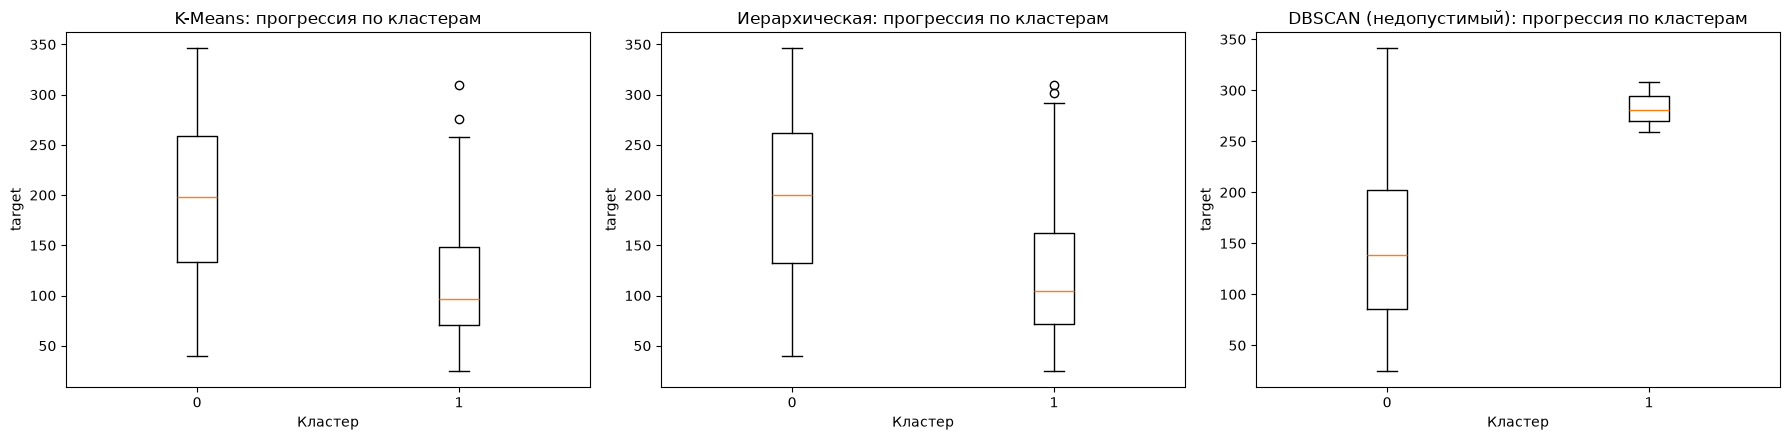

In [27]:
fig, axes = plt.subplots(1, len(final), figsize=(6 * len(final), 4.5), squeeze=False)
for ax, (name, labels) in zip(axes[0], final.items()):
    cl = [c for c in sorted(set(labels)) if c != -1]
    ax.boxplot([y[labels == c] for c in cl], tick_labels=[str(c) for c in cl])
    ax.set_title(f'{name}: прогрессия по кластерам')
    ax.set_xlabel('Кластер'); ax.set_ylabel('target')
plt.tight_layout()
plt.show()

In [28]:

rng = np.random.default_rng(RANDOM_STATE)
for _, r in best.dropna(subset=['Silhouette']).iterrows():
    k = int(r['Кластеров'])
    rand_eta = np.mean([target_check(rng.integers(0, k, len(y)), y)['eta2 (target)'] for _ in range(200)])
    print(f"{r['Метод']:14s} η² = {r['eta2 (target)']:.3f}   (случайное разбиение на {k} группы: η² ≈ {rand_eta:.3f})"
          f"   p-value = {r['p-value (Kruskal)']:.2e}")

K-Means        η² = 0.284   (случайное разбиение на 2 группы: η² ≈ 0.002)   p-value = 6.21e-28
Иерархическая  η² = 0.218   (случайное разбиение на 2 группы: η² ≈ 0.003)   p-value = 2.16e-21
DBSCAN         η² = 0.021   (случайное разбиение на 2 группы: η² ≈ 0.002)   p-value = 8.69e-03


In [29]:
overall = best[best['Допустим']].sort_values('Silhouette', ascending=False).iloc[0]
print('Лучший вариант по силуэту:', overall['Метод'], '|', overall['Параметры'])
print(f"Silhouette = {overall['Silhouette']:.3f}, кластеров = {int(overall['Кластеров'])}, "
      f"η² прогрессии = {overall['eta2 (target)']:.3f}")

best_labels = labels_for(overall)
result = data.assign(Кластер=best_labels)
result.head(10)

Лучший вариант по силуэту: K-Means | k=2
Silhouette = 0.332, кластеров = 2, η² прогрессии = 0.284


,bmi,bp,s6,target,Кластер
0,32.1,101.0,87.0,151.0,0
1,21.6,87.0,69.0,75.0,1
2,30.5,93.0,85.0,141.0,0
3,25.3,84.0,89.0,206.0,1
4,23.0,101.0,80.0,135.0,1
5,22.6,89.0,68.0,97.0,1
6,22.0,90.0,82.0,138.0,1
7,26.2,114.0,92.0,63.0,0
8,32.1,83.0,94.0,110.0,0
9,30.0,85.0,88.0,310.0,1
